## Imports

In [2]:
!pip3 install pandas matplotlib seaborn numpy scikit-learn


Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 926.1 kB/s eta 0:00:0031m1.1 MB/s eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 4.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.5/113.5 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 30.3 MB/s eta 0:00:00m eta 0:00:0136m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 34.1 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 50.3 MB/s eta 0:00:00 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 47.6 MB/s eta 0:00:001m49.6 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.3/249.3 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate, cross_val_score

# Doğrusal Regresyon (Linear Regression)

🎯 Bu egzersizde, bir NBA oyuncusunun win rating (`win_rating`) performansını, oynadığı dakika (`mp`) gibi maç istatistiklerine göre modelleyeceksiniz.


👉 [NBA.csv](https://d32aokrjazspmn.cloudfront.net/materials/NBA.csv) dataset’ini bu notebook’a bir pandas dataframe olarak yükleyin ve ilk 5 satırını görüntüleyin.

In [6]:
!ls *.csv

NBA .csv


In [8]:
df = pd.read_csv('NBA.csv')
df.head()


,season,poss,mp,do_ratio,pacing,win_rating
0,1987,4847,2409,-1.546275,-0.599918,1.643091
1,2017,5582,2708,0.996587,0.531888,10.808427
2,2016,4976,2407,0.242598,0.127976,3.054773
3,2021,1178,585,-1.343806,-1.201034,0.230004
4,1988,4534,2056,-1.813990,-0.128997,0.905614


ℹ️ Dataset’in detaylı açıklamasını challenge README dosyasında bulabilirsiniz. Challenge boyunca buna mutlaka referans verin.


## 1. Özellik Setini ve Hedefi Tanımlayın (Define Feature Set and Target)

🎯 İlk hedef, oyuncuların akranlarına kıyasla genel performans puanı olan *Wins Above Replacement* (`win_rating`) değerini, oynadıkları dakika sayısına (`mp`) göre modellemektir.

👉 Bu iki değişkeni `X` ve `y` olarak atayın. `X`’in feature(lar), `y`’nin ise target olduğunu unutmayın.

In [10]:
X = df[['mp']] #feature (independent) variable
y = df['win_rating'] #target (dependent variable)

👉 Bir [scatter plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) kullanarak rating ile oynanan dakika sayısı arasındaki ilişkiyi görselleştirin.

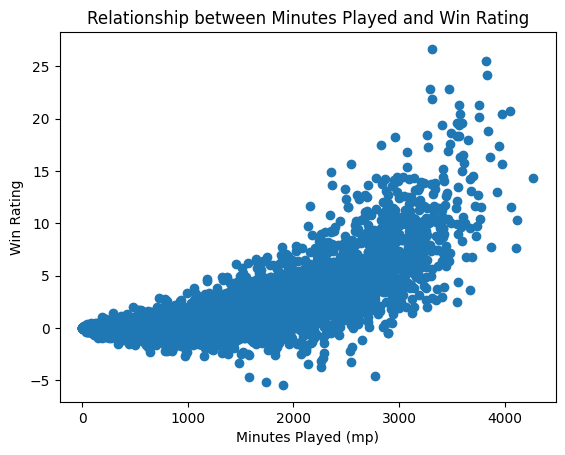

In [11]:
plt.scatter(X, y)
plt.xlabel('Minutes Played (mp)')
plt.ylabel('Win Rating')
plt.title('Relationship between Minutes Played and Win Rating')
plt.show()


ℹ️ Scatter plot, aralarında bir ilişki olduğunu düşündürmeli. Ancak bu ilişki tamamen doğrusal mı? 🤔 Göreceğiz!

## 2. Çapraz Doğrulama (Cross-Validation)

👉 Sklearn’in [`cross_validate`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html) fonksiyonunu kullanarak, oyuncu performans rating’ini oynanan dakika sayısına göre tahmin eden bir [`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) modeli üzerinde 5-fold cross-validation çalıştırın. Cross-validation’ın ham çıktısını `cv_results` adlı yeni bir değişkende saklayın.

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate

# Create the model
model = LinearRegression()

# Perform 5-fold cross-validation
cv_results = cross_validate(model, X, y, cv=5, return_train_score=True)

# Display the results
print(cv_results)

{'fit_time': array([0.00614285, 0.00134897, 0.00131512, 0.00293708, 0.00145102]), 'score_time': array([0.00149107, 0.00086808, 0.00085974, 0.00120974, 0.00097895]), 'test_score': array([0.5555057 , 0.53447908, 0.53790391, 0.57658459, 0.57917762]), 'train_score': array([0.56003925, 0.56367302, 0.5653569 , 0.55561258, 0.55502215])}


❓ Cross-validation sonuçları içindeki en düşük skor nedir?  
Cevabınızı hesaplayın ve değeri `min_score` adlı yeni bir değişkende saklayın.

In [13]:
# Get the minimum test score
min_score = cv_results['test_score'].min()

print("Minimum score:", min_score)

Minimum score: 0.5344790822272503


❓ Cross-validation sonuçları içindeki en yüksek skor nedir?  
Cevabınızı hesaplayın ve değeri `max_score` adlı yeni bir değişkende saklayın.

In [14]:
# Get the maximum test score
max_score = cv_results['test_score'].max()

print("Maximum score:", max_score)

Maximum score: 0.5791776193355005


❓ Cross-validation sonuçlarının ortalama skoru nedir?  
Cevabınızı hesaplayın ve değeri `mean_score` adlı yeni bir değişkende saklayın.

In [15]:
# Get the mean test score
mean_score = cv_results['test_score'].mean()

print("Mean score:", mean_score)

Mean score: 0.5567301800068911


ℹ️ Cross-validation çalıştırırken, model performansının en sağlam ve en temsil edici değerlendirmesi olarak her zaman ortalama skora bakarız.

### ☑️ Kodunu Test Et

In [17]:
!pip3 install nbresult


Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 23.3.1 -> 25.3
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip


In [18]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'cv_results',
    cv_result = cv_results,
    mean_score = mean_score
)

result.write()
print(result.check())


============================= test session starts ==============================
platform darwin -- Python 3.9.6, pytest-8.4.2, pluggy-1.6.0 -- /Library/Developer/CommandLineTools/usr/bin/python3
cachedir: .pytest_cache
rootdir: /Users/idildundar/Desktop/week16/S16D1-S-data-linear-regression/tests
plugins: anyio-4.12.0
collecting ... collected 2 items

test_cv_results.py::TestCvResults::test_cv_mean PASSED                   [ 50%]
test_cv_results.py::TestCvResults::test_cv_results PASSED                [100%]

============================== 2 passed in 0.09s ===============================


💯 You can commit your code:

git add tests/cv_results.pickle

git commit -m 'Completed cv_results step'

git push origin master



🤔 **Şimdi K-fold sayısının `K` (yani `cross_validate()` içindeki `cv` parametresi) etkisini inceleyelim**

👉 `K` değeri 2’den 20’ye çıkarken **<u>toplam</u> hesaplama süresinin (fit + score)** ve **<u>ortalama</u> skorun** nasıl değiştiğini plot edin.

<details>
  <summary markdown='span'><strong>İpucu</strong></summary>

  1. `K` değerlerini, hesaplama sürelerini ve cv ortalama skorlarını saklamak için 3 liste oluşturun.
  1. 2’den 20’ye kadar `K` değerleri üzerinde döngü kurun ve her seferinde:
     1. Cross-validation çalıştırın.
     1. `fit_time` ve `score_time` toplamını, toplam süreler listenize ekleyin.
     1. Ortalama `test_score` değerini, cv ortalama skorları listenize ekleyin.
  1. İki adet plot oluşturun:
     1. `K`’ye karşı toplam süre.
     1. `K`’ye karşı ortalama skor.
</details>


In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate
import numpy as np

# Test different K values
k_values = [2, 3, 5, 10, 20]

for k in k_values:
    model = LinearRegression()
    cv_results = cross_validate(model, X, y, cv=k, return_train_score=True)
    
    print(f"\n=== K = {k} ===")
    print(f"Test scores: {cv_results['test_score']}")
    print(f"Mean score: {cv_results['test_score'].mean():.4f}")
    print(f"Std deviation: {cv_results['test_score'].std():.4f}")
    print(f"Min score: {cv_results['test_score'].min():.4f}")
    print(f"Max score: {cv_results['test_score'].max():.4f}")


=== K = 2 ===
Test scores: [0.55607054 0.56112015]
Mean score: 0.5586
Std deviation: 0.0025
Min score: 0.5561
Max score: 0.5611

=== K = 3 ===
Test scores: [0.55352584 0.54579088 0.57668144]
Mean score: 0.5587
Std deviation: 0.0131
Min score: 0.5458
Max score: 0.5767

=== K = 5 ===
Test scores: [0.5555057  0.53447908 0.53790391 0.57658459 0.57917762]
Mean score: 0.5567
Std deviation: 0.0187
Min score: 0.5345
Max score: 0.5792

=== K = 10 ===
Test scores: [0.53703565 0.57079142 0.51180405 0.55707981 0.57846267 0.49927082
 0.57110196 0.58313621 0.56420198 0.59579423]
Mean score: 0.5569
Std deviation: 0.0298
Min score: 0.4993
Max score: 0.5958

=== K = 20 ===
Test scores: [0.58291225 0.47907918 0.57412048 0.56645869 0.50268829 0.52837563
 0.58236308 0.53312956 0.56010833 0.59782935 0.48301643 0.52235428
 0.65666811 0.51118652 0.59870084 0.55833788 0.57461751 0.54706921
 0.59136494 0.59740975]
Mean score: 0.5574
Std deviation: 0.0433
Min score: 0.4791
Max score: 0.6567


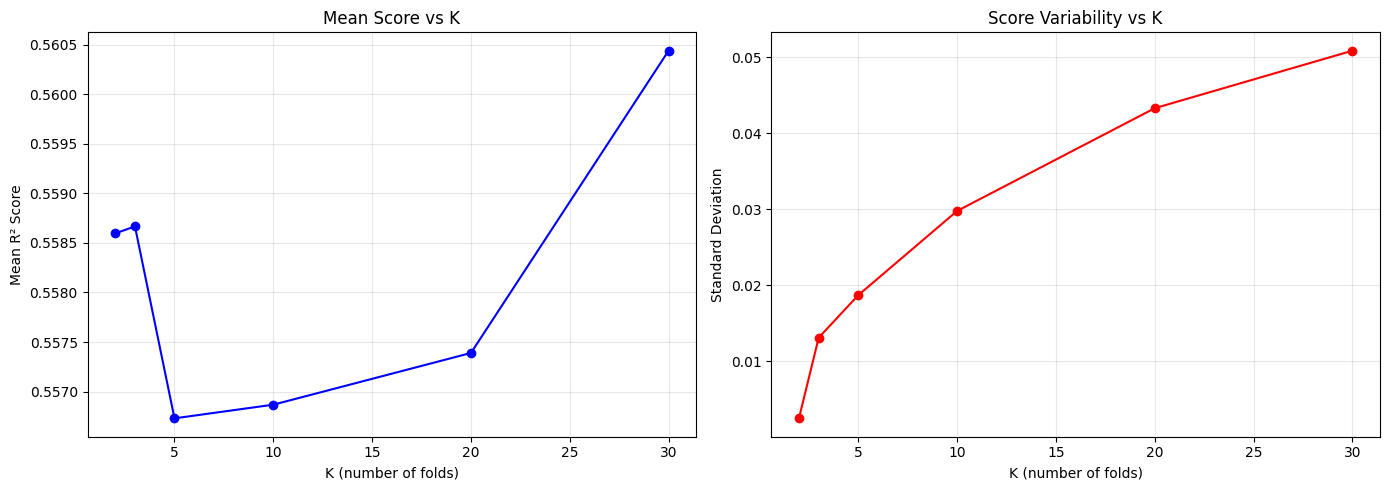

In [20]:
import matplotlib.pyplot as plt

k_values = [2, 3, 5, 10, 20, 30]
mean_scores = []
std_scores = []

for k in k_values:
    model = LinearRegression()
    cv_results = cross_validate(model, X, y, cv=k)
    mean_scores.append(cv_results['test_score'].mean())
    std_scores.append(cv_results['test_score'].std())

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Mean scores
ax1.plot(k_values, mean_scores, marker='o', color='blue')
ax1.set_xlabel('K (number of folds)')
ax1.set_ylabel('Mean R² Score')
ax1.set_title('Mean Score vs K')
ax1.grid(True, alpha=0.3)

# Standard deviation
ax2.plot(k_values, std_scores, marker='o', color='red')
ax2.set_xlabel('K (number of folds)')
ax2.set_ylabel('Standard Deviation')
ax2.set_title('Score Variability vs K')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

ℹ️ $R^2$ skorunun sabit kaldığını görmelisiniz; bu, modelin hem daha küçük hem de daha büyük test setlerinde benzer performans gösterdiğinin iyi bir işaretidir. Buna karşılık, hesaplama süresi artmaya devam eder. Bu nedenle, pratik bir kural olarak genellikle K = 10’un üzerine çıkmayız.

## 3. Modeli eğit (Train the Model)

Cross-validation, veri seti üzerinde varsayımsal bir modeli değerlendirmek için kullanılır. Seçtiğiniz fold sayısı kadar modeli birden fazla kez eğitir; her seferinde verinin farklı bir alt kümesi üzerinde eğitilir ve kalan veriyle skor hesaplanır. Bu süreç bize, modelin ne kadar iyi performans gösterebileceğini gösteren cross-validated bir skor verir.

Ancak modeli gerçek anlamda tahmin yapmak için kullanmak istediğinizde, mümkün olduğunca fazla veriyle eğitmeyi tercih edersiniz. Yani verinin bir kısmını ayırmadan.

👉 Modeli, tam `X` ve `y` üzerinde eğitin (model skorunu zaten doğruladık, şimdi tahmin için kullanacağız). Eğitilmiş modeli `model` adlı değişkende saklayın.

In [23]:
# SENİN KODUN BURAYA
from sklearn.linear_model import LinearRegression

# Create and train the model on ALL data
model = LinearRegression()
model.fit(X, y)

print("Model trained successfully!")
print(f"Coefficient (slope): {model.coef_[0]:.6f}")
print(f"Intercept: {model.intercept_:.6f}")


Model trained successfully!
Coefficient (slope): 0.002603
Intercept: -1.546375


❓ Eğitilmiş modelinizin eğimi (slope) ya da katsayısı (coefficient) nedir?  
Bu değere modelin attribute’ları üzerinden erişebilirsiniz. Eğimi `slope` adlı bir değişkende saklayın.

In [24]:
# Get the slope (coefficient)
slope = model.coef_[0]

print("Slope:", slope)


Slope: 0.0026025799386401927


❓ Eğitilmiş modelinizin intercept (sabit terim) değeri nedir?  
Bu değere modelin attribute’ları üzerinden erişebilirsiniz. Intercept değerini `intercept` adlı bir değişkende saklayın.

In [27]:
intercept = model.intercept_
print(f"Intercept: {model.intercept_:.6f}")


Intercept: -1.546375


🤔 Devam etmeden önce bu katsayıları nasıl yorumlayacağınızı anladığınızdan emin olun.

### ☑️ Kodunu Test Et

In [28]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'trained_model',
    slope = slope,
    intercept = intercept
)

result.write()
print(result.check())


============================= test session starts ==============================
platform darwin -- Python 3.9.6, pytest-8.4.2, pluggy-1.6.0 -- /Library/Developer/CommandLineTools/usr/bin/python3
cachedir: .pytest_cache
rootdir: /Users/idildundar/Desktop/week16/S16D1-S-data-linear-regression/tests
plugins: anyio-4.12.0
collecting ... collected 2 items

test_trained_model.py::TestTrainedModel::test_intercept PASSED           [ 50%]
test_trained_model.py::TestTrainedModel::test_slope PASSED               [100%]

============================== 2 passed in 0.10s ===============================


💯 You can commit your code:

git add tests/trained_model.pickle

git commit -m 'Completed trained_model step'

git push origin master



## 4. Tahmin (Predict)

👉 Eğitilmiş modelinizi kullanarak toplamda 1000 dakika oynamış bir oyuncunun performans rating’ini tahmin edin.  
Tahmin edilen değeri `prediction` adlı bir değişkende saklayın.

In [31]:
new_datapoint = pd.DataFrame.from_dict(
    {"mp": [1000]}
)

prediction = model.predict(new_datapoint)[0]

print(f"Predicted win rating: {prediction}")

Predicted win rating: 1.0562050014762487


### ☑️ Kodunu Test Et

In [35]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'prediction',
    prediction = prediction
)

result.write()
print(result.check())


============================= test session starts ==============================
platform darwin -- Python 3.9.6, pytest-8.4.2, pluggy-1.6.0 -- /Library/Developer/CommandLineTools/usr/bin/python3
cachedir: .pytest_cache
rootdir: /Users/idildundar/Desktop/week16/S16D1-S-data-linear-regression/tests
plugins: anyio-4.12.0
collecting ... collected 1 item

test_prediction.py::TestPrediction::test_prediction PASSED               [100%]

============================== 1 passed in 0.12s ===============================


💯 You can commit your code:

git add tests/prediction.pickle

git commit -m 'Completed prediction step'

git push origin master



## 5.  Daha Fazla Özellik ile Modeli İyileştirme (Improving the Model with More Features)

NBA fantasy league’i seven bir arkadaşınız size bazı içgörülerle geliyor 🏀

Bir oyuncunun *Wins Above Replacement* rating’ini değerlendirirken, genellikle topa sahip olma sayısına (`poss`), savunma/hücum oranına (`do_ratio`) ve `pacing` değerine de baktıklarını söylüyor.

❓ Aşağıdaki hücreyi çalıştırarak bu yeni feature’lar ile `win_rating` arasındaki korelasyonu görselleştirin.  
Yukarıdaki feature’lardan **hangisini** modelinize eklemeyi düşünürdünüz?

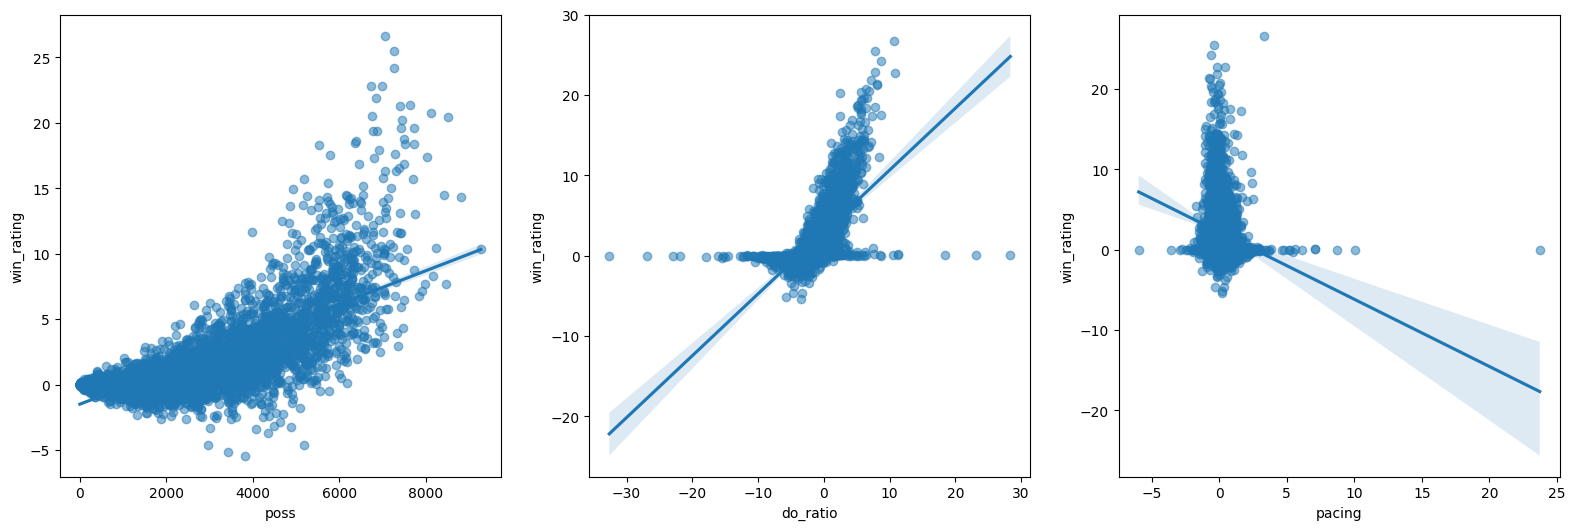

In [37]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(10, 6))

plt.subplots_adjust(left=0.5, right=2)

sns.regplot(data=df, y='win_rating', x='poss', ax=axes[0], scatter_kws={'alpha':0.5})
sns.regplot(data=df, y='win_rating', x='do_ratio', ax=axes[1], scatter_kws={'alpha':0.5})
sns.regplot(data=df, y='win_rating', x='pacing', ax=axes[2], scatter_kws={'alpha':0.5})

plt.show()

<details>
  <summary markdown='span'><strong>Cevap</strong></summary>

  Feature’ları manuel olarak seçecek olsaydınız, hedef değişken olan `win_rating` ile en yüksek korelasyona sahip olanlarla başlardınız.

  Regresyon plot’larına baktığımızda, geriye `poss` ve `do_ratio` kalıyor. Sayısal değerleri görmek isterseniz `df.corr()[['win_rating']]` çıktısına bakabilirsiniz.

  Peki neden `poss` değil? Sonuçta `win_rating` ile olan korelasyonu `do_ratio`’dan daha yüksek.

  Bir de şuna bakın: `sns.scatterplot(data=df, x='mp', y='poss');`. Nedenini görebiliyor musunuz?

  <details>
  <summary><strong>Cevap</strong></summary>

  Görünen o ki, ilk feature’ımız olan `mp` ile `poss` neredeyse mükemmele yakın şekilde korelasyonlu. Bu yüzden `poss`, modele çok az ek değer katacaktır.

  </details>

</details>

Şimdi, iki feature kullanan modelin (seçtiğiniz yeni feature ve `mp`) bir oyuncunun rating’ini tahmin etmede ilk modelimizden daha iyi olup olmadığına bakalım.

👉 İki sütunlu bir DataFrame olacak şekilde yeni bir feature set’i oluşturun.

In [38]:
# SENİN KODUN BURAYA
X = df[['mp', 'do_ratio']]  # 2 sütunlu DataFrame
y = df['win_rating']
print(X.shape)  # (n_rows, 2) olmalı - 2 feature!
print(X.head())

(4000, 2)
     mp  do_ratio
0  2409 -1.546275
1  2708  0.996587
2  2407  0.242598
3   585 -1.343806
4  2056 -1.813990


👉 Şimdi yeni bir linear regression modeli için cross-validation çalıştırın ve **ortalama** skoru `mean_2_feat_score` değişkenine kaydedin.

> Not: Eğer sadece cross-validation skoruyla ilgileniyorsanız (hesaplama süreleriyle değil), sklearn’in [`cross_val_score`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html) fonksiyonunu kullanabilirsiniz.

In [41]:
# SENİN KODUN BURAYA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

# Create new model
model = LinearRegression()

# Run cross-validation with 2 features
scores = cross_val_score(model, X, y, cv=5)

# Calculate mean score
mean_2_feat_score = scores.mean()

print("Individual scores:", scores)
print("Mean score (2 features):", mean_2_feat_score)

print("=== Model Comparison ===")
print(f"1 Feature (mp only):           R² = {mean_score:.4f}")
print(f"2 Features (mp + do_ratio):    R² = {mean_2_feat_score:.4f}")
print(f"Improvement:                   +{mean_2_feat_score - mean_score:.4f}")



Individual scores: [0.64623763 0.62713011 0.57717502 0.65851969 0.6498017 ]
Mean score (2 features): 0.6317728310765245
=== Model Comparison ===
1 Feature (mp only):           R² = 0.5567
2 Features (mp + do_ratio):    R² = 0.6318
Improvement:                   +0.0750


### ☑️ Kodunu Test Et

In [42]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'improved_score',
    improved_score = mean_2_feat_score
)

result.write()
print(result.check())


============================= test session starts ==============================
platform darwin -- Python 3.9.6, pytest-8.4.2, pluggy-1.6.0 -- /Library/Developer/CommandLineTools/usr/bin/python3
cachedir: .pytest_cache
rootdir: /Users/idildundar/Desktop/week16/S16D1-S-data-linear-regression/tests
plugins: anyio-4.12.0
collecting ... collected 1 item

test_improved_score.py::TestImprovedScore::test_improved_score PASSED    [100%]

============================== 1 passed in 0.10s ===============================


💯 You can commit your code:

git add tests/improved_score.pickle

git commit -m 'Completed improved_score step'

git push origin master



$R^2$ değerinizde **yaklaşık %8’lik bir artış** görmelisiniz 👏

Tebrikler, ilk manuel *feature selection* işleminizi gerçekleştirdiniz — bu hafta bunun daha birçok yolunu göreceğiz!

🤔 Peki Linear Regression ile yapabileceğimiz en iyi şey bu mu? Bir sonraki challenge’da bunu daha derinlemesine keşfedelim!

# 🏁